# Subproduto 5 — Inteligência para priorização e melhoria da estratégia de manutenção

**Entrada:** as bases de `processamento_inicial.ipynb` (`mes_registros`, `mes_paradas`, `sap_ordens`) e o algoritmo de `conciliacao.py` (Subproduto 2), que liga as anotações da Produção (MES) com as da Manutenção (SAP). As regras deste notebook ficam em `priorizacao.py`, para o app reaproveitar sem copiar código.

O case pede três frentes:

1. **Ranking dinâmico de problemas:** "se a Engenharia puder atacar só alguns problemas neste período, quais e por quê?"
2. **Sinais de deterioração:** quebras mais frequentes, intervalos menores e reparos mais demorados, transformados em alertas.
3. **Efetividade das preventivas:** as atividades planejadas reduzem as quebras seguintes?

**Unidade de análise:** o **componente de uma máquina** (máquina + componente do MES). É o nível em que a Engenharia age: é o componente que se inspeciona, troca ou monitora, e não "a máquina inteira". Os rankings por equipamento e por máquina saem da mesma função, só mudando o agrupamento.

**Quebra:** parada do MES com algum registro da família QUEBRA, sem contar micro-paradas (menos de 2 min). Os ajustes ficam de fora porque não indicam falha do componente (são pequenas regulagens do operador/manutenção).

### Resumo dos resultados

1. **Ranking.** Os primeiros colocados do semestre são **na máquina D** o *TRP-MAN*, e *DOS-ATU* e na **máquina A** o *FBPB*. Na máquina A, os quatro primeiros são *FBPB*, *CLH*, *LMDTR* e *FD*. Mesmo variando os pesos dos critérios em torno da proposta (Definidos pelo método AHP, seção 1.2), 7 dos 10 primeiros continuam no top 10 em pelo menos 90% das variações, e os rankings sorteados ficam praticamente iguais ao original (correlação mediana de 0,99, numa escala em que 1 = idênticos). Olhando só os últimos 90 dias, a máquina D passou de 0 para 6 itens no top 10 entre abril e junho.
2. **Deterioração.** 10 dos 74 componentes testados estão em alerta, já descontados os "falsos alarmes" esperados por fazer muitos testes ao mesmo tempo. Em dados simulados sem nenhuma piora, o procedimento dá em média só 0,07 alarme falso por semestre. Na máquina A, os alertas são FBPB (4 quebras no 1º trimestre, 11 no 2º), GRAL e LOF.
3. **O problema da máquina A é crônico, não de piora.** As quebras da A, no conjunto, não aumentaram. Mas **51% delas voltam no mesmo componente em até 7 dias**, contra 20–40% nas outras máquinas, e o CLH chega a 76%. É o ciclo "reparo, retorno, nova falha" descrito no case.
4. **Preventivas.** A base do SAP **não tem nenhuma ordem preventiva**. Na comparação possível, uma intervenção planejada não aumenta de forma significativa o tempo até a próxima quebra do componente, comparada a um reparo emergencial (teste log-rank estratificado, p = 0,18, ou seja, a diferença observada está dentro do que o acaso explica). Isso é coerente com reparos que tratam o sintoma.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

import scripts.priorizacao as pz
from scripts.conciliacao import conciliar, consolidar, carregar

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Cores para os gráfics :)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
STATUS = {"alerta": "#d03b3b", "atenção": "#fab219", "estável": "#0ca30c"}
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRADE,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

In [3]:
mes, paradas, sap = carregar("./data/processed/limpeza")
_, vinculo = conciliar(mes, paradas, sap)
eventos, _ = consolidar(mes, paradas, sap, vinculo)

q = pz.quebras(paradas)

# Janela de observação = o que o MES cobre. O fim é a última retomada registrada:
# estender até o fim do mês contaria dias sem dado como dias sem quebra.
INICIO = paradas["inicio"].min().normalize()
FIM = paradas["fim"].max()

# Criticidade da máquina: o mesmo C2 da priorização de chamados (campo "impacto" do cadastro no app).
IMPACTO = {"A": pz.IMPACTO_PADRAO["gargalo"], "B": pz.IMPACTO_PADRAO["sem_redundancia"],
           "C": pz.IMPACTO_PADRAO["sem_redundancia"], "D": pz.IMPACTO_PADRAO["sem_redundancia"]}

print(f"Janela: {INICIO:%d/%m/%Y} a {FIM:%d/%m/%Y %H:%M} ({(FIM - INICIO).days} dias)")
print(f"{len(paradas)} paradas -> {len(q)} quebras em {q.groupby(['maquina', 'componente']).ngroups} componentes")
print(eventos["classe"].value_counts().to_string())
q.groupby("maquina").agg(quebras=("id_parada", "size"), horas=("duracao_h", "sum"),
                         componentes=("componente", "nunique"))

Janela: 02/01/2026 a 28/06/2026 04:03 (177 dias)
1501 paradas -> 708 quebras em 112 componentes
classe
MES + SAP      1074
MES sem SAP     427
SAP sem MES     348


,quebras,horas,componentes
maquina,,,
A,162,391.02,29
B,191,194.93,27
C,147,444.13,26
D,208,448.19,30


## 1. Ranking dinâmico de problemas

### 1.1 Critérios

Nenhum número sozinho diz o que é mais urgente: um componente pode parar muito tempo mas quase nunca quebrar, outro pode quebrar toda semana por poucos minutos, e um terceiro pode estar piorando rápido. Por isso o ranking combina **quatro critérios**, cada um transformado numa nota de 0 a 1:

| Critério | Como é medido | Como vira nota de 0 a 1 | Por que entra |
|---|---|---|---|
| **C1 · Impacto** | total de horas paradas × criticidade da máquina (gargalo 1,0; sem máquina reserva 0,7; com máquina reserva 0,4) | ÷ maior valor do conjunto (o pior item vale 1) | É a perda de produção. Uma hora parada no **gargalo** (a máquina que limita a linha inteira) para a fábrica toda. |
| **C2 · Frequência** | número de quebras | ÷ maior valor | Cada quebra é uma intervenção sob pressão, com risco de segurança e de erro. |
| **C3 · Tendência** | estatística U do teste de Laplace (seção 2) | Φ(U), explicado abaixo: 0,5 = sem tendência; perto de 1 = piorando | Um problema que cresce deve subir no ranking **antes** de ficar grande. |
| **C4 · Reincidência** | fração das quebras que aconteceram a até 7 dias da anterior no mesmo componente | já é uma taxa (de 0 a 1); suavizada para a média da máquina (abaixo) | Repetição em poucos dias indica que a causa não foi resolvida. |

**Criticidade:** numa cozinha com um fogão só, se o fogão quebra, o jantar inteiro para (gargalo, peso 1,0). Se o micro-ondas quebra e existe outro, dá para contornar (com reserva, peso 0,4).

**O que é Φ(U):** o U do teste de Laplace pode ir de valores negativos a positivos sem limite. Φ é uma função que "espreme" qualquer número para o intervalo de 0 a 1, seguindo istribuição normal: U = 0 vira 0,5 (neutro), U = +2 vira ≈ 0,98 (quase certeza de piora), U = −2 vira ≈ 0,02 (melhorando). É como converter uma temperatura em "probabilidade de estar com febre".

**Por que o MTTR (tempo médio de reparo) não é um critério separado:** horas paradas = nº de quebras × MTTR. Com C1 (horas) e C2 (quebras) já no score, o MTTR está contado indiretamente; acrescentá-lo daria **peso duplo** à mesma informação, como contar a mesma prova duas vezes na média. Ele aparece na tabela só para explicar: o componente pesa por quebrar muito ou por demorar a voltar?

**Por que não há custo:** as bases não trazem custo de peças, de mão de obra nem de hora parada. Quando houver, o custo entra no lugar de C1 ou multiplica as horas.

**Suavização da reincidência:** um componente com 2 quebras, sendo 1 reincidente, teria 50%, um número alto apoiado em quase nada. Para evitar isso, a taxa é "puxada" para a média da máquina como se o componente tivesse **2 quebras fictícias** com a taxa média: (reincidentes + 2·média) ÷ (quebras + 2).

**Analogia:** é como a nota de um restaurante novo num aplicativo. Com 2 avaliações de 5 estrelas, ninguém acredita que ele é perfeito; o aplicativo mistura com a média geral até ele ter mais avaliações. Com muitas quebras, a suavização praticamente some.

**Tendência com poucos dados:** com menos de 4 quebras, o teste de tendência não consegue distinguir piora de acaso, e o C3 fica **neutro (0,5)**.

### 1.2 Pesos pelo AHP

Falta decidir **quanto cada critério vale** na nota final. Para isso usamos o **AHP** (*Analytic Hierarchy Process*, ou Processo de Análise Hierárquica), criado por Thomas Saaty nos anos 1970 para decisões com vários critérios.

**Como funciona, passo a passo:**

1. Em vez de pedir "dê um peso para cada critério" (difícil de fazer de cabeça), o AHP pede **comparações de dois em dois**: "Impacto é quantas vezes mais importante que Frequência?".
2. As respostas usam a **escala de Saaty**: 1 = igualmente importantes; 3 = um pouco mais importante; 5 = bem mais importante; 7 = muito mais; 9 = extremamente mais (2, 4, 6, 8 são valores intermediários). Se A é 3 vezes mais importante que B, então B é 1/3 de A.
3. As comparações formam uma tabela (matriz). Um cálculo de álgebra linear (o **autovetor principal** da matriz) transforma essa tabela nos pesos finais, que somam 1. Na prática, é uma forma de "tirar a média" de todas as comparações de um jeito que respeita as proporções entre elas.
4. O AHP ainda verifica a **coerência** das respostas pela **razão de consistência (CR)**. Se você diz que A > B (2×) e B > C (2×), então deveria dizer A > C (cerca de 4×). Se disser que C > A, há contradição. **CR abaixo de 0,10** significa que as comparações são coerentes entre si.


**Por que AHP aqui:** (1) é o **mesmo método** usado na classificação dos chamados do app, o que mantém a lógica coerente em todo o projeto; (2) comparar de dois em dois é mais fácil e mais honesto do que chutar pesos diretamente; (3) a verificação de consistência mostra se o julgamento faz sentido.

**Os julgamentos usados:** a ordem segue o que custa mais à fábrica. A perda de produção (C1) vem antes da frequência (C2), e esta antes dos dois sinais de causa não resolvida (C3 e C4), que têm a mesma importância entre si.

In [4]:
w, cr = pz.ahp(pz.MATRIZ_AHP)
nomes = [pz.ROTULOS[k] for k in pz.CRITERIOS]
matriz = pd.DataFrame(pz.MATRIZ_AHP, index=nomes, columns=nomes)
matriz["peso"] = w
print(f"Razão de consistência CR = {cr:.3f} (limite 0,10)")
matriz

Razão de consistência CR = 0.004 (limite 0,10)


,Impacto,Frequência,Tendência,Reincidência,peso
Impacto,1.00,2.00,3.00,3.00,0.46
Frequência,0.50,1.00,2.00,2.00,0.26
Tendência,0.33,0.50,1.00,1.00,0.14
Reincidência,0.33,0.50,1.00,1.00,0.14


**Como ler a tabela:** cada célula diz quantas vezes o critério da **linha** é mais importante que o da **coluna** (por exemplo, Impacto × Frequência = 2: o impacto vale o dobro). A última coluna são os pesos finais: **Impacto 46%, Frequência 26%, Tendência 14% e Reincidência 14%**. A razão de consistência CR = 0,004 está muito abaixo do limite de 0,10, ou seja, as comparações são coerentes entre si.

### 1.3 Ranking do semestre

**Score de 0 a 100** = 100 × Σ (peso × nota do critério). Cada linha mostra também **quantos pontos vieram de cada critério** (colunas `pts_...`), no mesmo formato do cartão do chamado no app ("73 = parada 42 + gargalo 26 + …").

É como um boletim que mostra não só a nota final, mas quanto cada prova contribuiu para ela. Assim dá para explicar **por que** um componente está no topo.

In [5]:
c_semestre = pz.criterios(q, INICIO, FIM, IMPACTO)
r_semestre = pz.ranking(c_semestre, w)

colunas = ["posicao", "maquina", "componente", "score", "quebras", "horas", "mttr_h", "reincidentes",
           "laplace_U", "pts_C1_impacto", "pts_C2_frequencia", "pts_C3_tendencia", "pts_C4_reincidencia"]
r_semestre[colunas].head(15)

,posicao,maquina,componente,score,quebras,horas,mttr_h,reincidentes,laplace_U,pts_C1_impacto,pts_C2_frequencia,pts_C3_tendencia,pts_C4_reincidencia
0,1,D,TRP-MAN,96.51,27,73.59,2.73,21,4.18,45.54,26.28,14.09,10.59
1,2,D,DOS-ATU,80.55,27,50.17,1.86,18,3.97,31.05,26.28,14.09,9.14
2,3,A,FBPB,79.83,15,48.55,3.24,9,2.53,42.92,14.60,14.01,8.30
3,4,A,CLH,69.03,25,31.68,1.27,19,-0.14,28.01,24.34,6.24,10.44
4,5,A,LMDTR,62.70,11,42.13,3.83,5,0.21,37.25,10.71,8.23,6.52
5,6,D,DOS-VLV,62.06,14,42.98,3.07,8,3.17,26.60,13.63,14.08,7.76
6,7,C,TRM-EIX,57.63,15,37.40,2.49,7,1.99,23.14,14.60,13.76,6.13
7,8,D,TRP-COR,56.17,13,40.53,3.12,4,2.25,25.08,12.65,13.91,4.52
8,9,A,FD,53.77,22,17.60,0.80,15,0.06,15.56,21.42,7.40,9.40
9,10,A,RDFD,53.71,10,39.95,4.00,6,-1.88,35.32,9.73,0.42,8.23


**Como ler o gráfico abaixo:** cada barra é um componente (os 15 primeiros), e as cores mostram quantos pontos vieram de cada critério. O número na ponta é o score total.

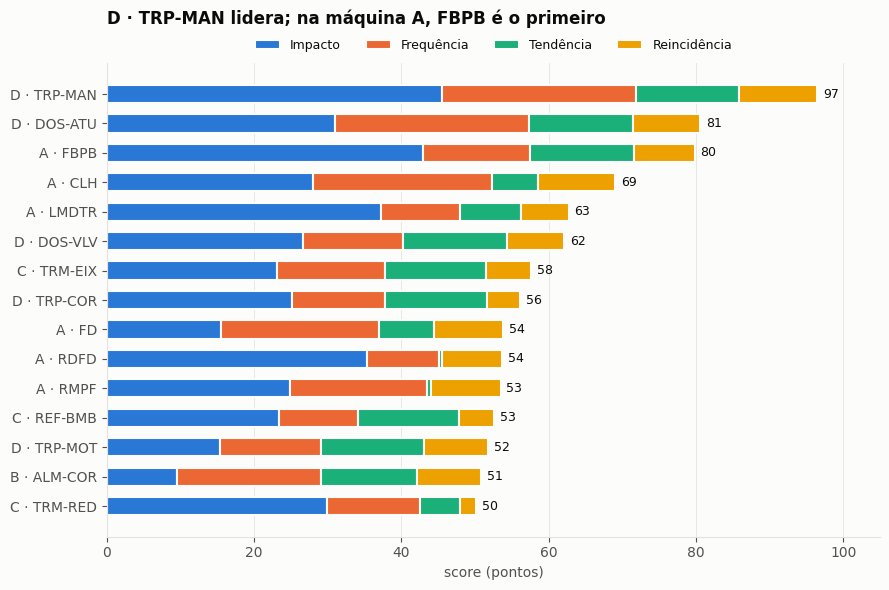

In [6]:
TOP = 15
top = r_semestre.head(TOP).iloc[::-1]
rotulos = top["maquina"] + " · " + top["componente"]

fig, ax = plt.subplots(figsize=(9, 6))
esquerda = np.zeros(len(top))
for k, cor in zip(pz.CRITERIOS, CAT):
    v = top[f"pts_{k}"].to_numpy()
    ax.barh(rotulos, v, left=esquerda, color=cor, height=0.62, edgecolor="#fcfcfb", linewidth=1.5,
            label=pz.ROTULOS[k])
    esquerda += v
for y, total in enumerate(esquerda):
    ax.text(total + 0.8, y, f"{total:.0f}", va="center", fontsize=9, color=TINTA)
ax.set_xlim(0, 105)
ax.set_xlabel("score (pontos)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
lider = r_semestre.iloc[0]
ax.set_title(f"{lider.maquina} · {lider.componente} lidera; na máquina A, "
             f"{r_semestre.loc[r_semestre.maquina == 'A'].iloc[0].componente} é o primeiro", pad=28)
plt.tight_layout()

### 1.4 O ranking depende dos pesos escolhidos?

Os pesos do AHP são um **julgamento** humano. Outra pessoa poderia achar que a frequência vale um pouco mais, ou o impacto um pouco menos. Se o ranking mudasse completamente com qualquer mudança pequena de opinião, ele não serviria para decidir nada.

**O teste:** sorteamos **2.000 conjuntos de pesos** parecidos com os do AHP e recalculamos o ranking para cada um. Os sorteios usam a **distribuição de Dirichlet**, que é uma "máquina de sortear pesos" com duas garantias: os pesos sorteados são sempre positivos e **sempre somam 1**, e ficam **em torno** dos pesos do AHP. A "concentração 40" controla o quanto eles se afastam: cada peso varia cerca de ±30% do seu valor.

É como pedir a 2.000 engenheiros, cada um com uma opinião um pouco diferente sobre a importância dos critérios, que refaçam o ranking. Se quase todos colocam os mesmos componentes no topo, a conclusão não depende de quem fez a conta.

Duas medidas resumem o resultado:
- **Correlação de Spearman** entre o ranking original e cada ranking sorteado: mede se as duas listas estão **na mesma ordem**. Vai de −1 (ordem invertida) a +1 (ordem idêntica).
- **Frequência no top 10** de cada componente: em quantos dos 2.000 sorteios ele ficou entre os 10 primeiros.

In [7]:
sens, rho = pz.sensibilidade_pesos(c_semestre, w, n_sorteios=2000, concentracao=40, top=10)
sens = sens.merge(r_semestre[["maquina", "componente", "posicao"]], on=["maquina", "componente"])
print(f"Correlação de Spearman entre o ranking base e os sorteados: mediana {np.median(rho):.3f}, "
      f"5% dos sorteios abaixo de {np.percentile(rho, 5):.3f}")
estaveis = sens.query("posicao <= 10 and freq_top >= 0.9")
print(f"Do top 10 base, {len(estaveis)} itens ficam no top 10 em pelo menos 90% dos sorteios.")
sens.sort_values("posicao").head(15)[["posicao", "maquina", "componente", "freq_top", "pos_mediana", "pos_p10", "pos_p90"]]

Correlação de Spearman entre o ranking base e os sorteados: mediana 0.990, 5% dos sorteios abaixo de 0.966
Do top 10 base, 7 itens ficam no top 10 em pelo menos 90% dos sorteios.


,posicao,maquina,componente,freq_top,pos_mediana,pos_p10,pos_p90
106,1,D,TRP-MAN,1.00,1.00,1.00,1.00
85,2,D,DOS-ATU,1.00,2.00,2.00,3.00
8,3,A,FBPB,1.00,3.00,2.00,3.00
2,4,A,CLH,1.00,4.00,4.00,5.00
17,5,A,LMDTR,0.98,5.00,5.00,7.00
88,6,D,DOS-VLV,1.00,6.00,5.00,7.00
79,7,C,TRM-EIX,0.99,7.00,7.00,9.00
105,8,D,TRP-COR,0.77,9.00,8.00,11.00
9,9,A,FD,0.45,11.00,8.00,14.00
25,10,A,RDFD,0.51,10.00,7.00,16.00


**O que a saída mostra:** a correlação mediana entre o ranking original e os sorteados é 0,99 (as listas ficam quase idênticas), e mesmo nos 5% de sorteios mais "diferentes" ela fica acima de 0,96. Dos 10 primeiros, 7 aparecem no top 10 em pelo menos 90% dos sorteios.

Na tabela, `freq_top` é a fração dos sorteios em que o item ficou no top 10; `pos_mediana` é a posição típica; `pos_p10` e `pos_p90` delimitam a faixa em que o item ficou em 80% dos sorteios (excluindo os 10% mais otimistas e os 10% mais pessimistas).

**Como ler o gráfico abaixo:** o ponto é a posição com os pesos do AHP e a linha horizontal mostra entre quais posições o componente variou em 80% dos sorteios. Linha curta = posição firme. A linha tracejada marca o corte do top 10.

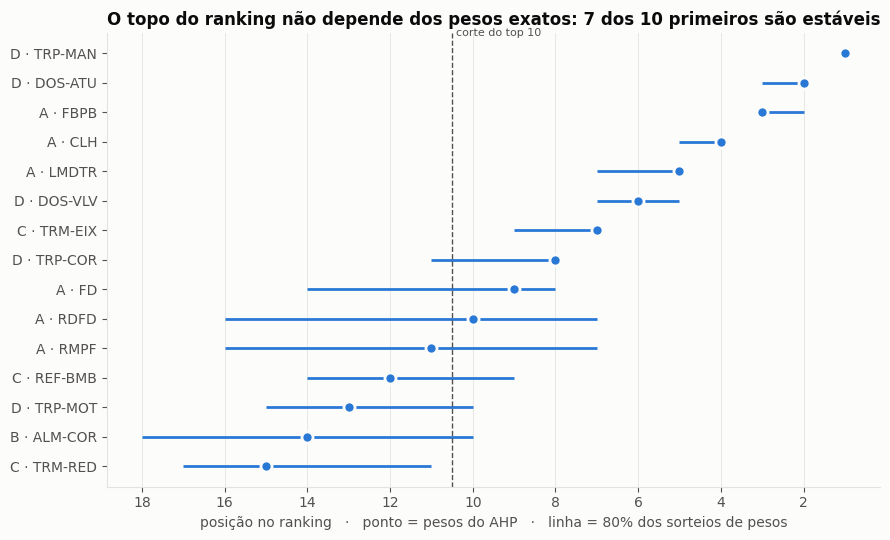

In [8]:
s = sens.sort_values("posicao").head(TOP).iloc[::-1]
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hlines(y, s["pos_p10"], s["pos_p90"], color=CAT[0], linewidth=2)
ax.plot(s["posicao"], y, "o", color=CAT[0], markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.set_yticks(y, s["maquina"] + " · " + s["componente"])
ax.invert_xaxis()
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.axvline(10.5, color=TINTA_2, linewidth=1, linestyle="--")
ax.text(10.4, len(s) - 0.4, "corte do top 10", fontsize=8, color=TINTA_2)
ax.set_xlabel("posição no ranking   ·   ponto = pesos do AHP   ·   linha = 80% dos sorteios de pesos")
ax.grid(axis="y", visible=False)
ax.set_title(f"O topo do ranking não depende dos pesos exatos: {len(estaveis)} dos 10 primeiros são estáveis")
plt.tight_layout()

**O que o ranking de vários critérios muda em relação a um Pareto de horas paradas:** o Pareto (ordenar só pelas horas paradas, a regra "poucos causam a maior parte da perda") olha apenas o C1. O ranking faz subir também os componentes que **quebram muito e reincidem**, e os que **estão piorando**, mesmo antes de acumularem muitas horas. A célula abaixo mostra quais itens entram e saem do top 10 quando trocamos o Pareto pelo ranking.

In [9]:
pareto = c_semestre.assign(h_pond=c_semestre["horas"] * c_semestre["impacto_maquina"]) \
                   .sort_values("h_pond", ascending=False).head(10)
chave = lambda d: set(d["maquina"] + " · " + d["componente"])
so_ranking = chave(r_semestre.head(10)) - chave(pareto)
so_pareto = chave(pareto) - chave(r_semestre.head(10))
print("Entram no top 10 pelo ranking, mas não pelo Pareto de horas:", ", ".join(sorted(so_ranking)) or "nenhum")
print("Saem do top 10 em relação ao Pareto de horas:              ", ", ".join(sorted(so_pareto)) or "nenhum")

Entram no top 10 pelo ranking, mas não pelo Pareto de horas: A · FD, C · TRM-EIX
Saem do top 10 em relação ao Pareto de horas:               A · EXESD, C · TRM-RED


### 1.5 Ranking dinâmico: os últimos 90 dias, recalculados a cada mês

"Dinâmico" quer dizer que o ranking é **recalculado periodicamente** olhando sempre só os **últimos 90 dias**, uma "janela móvel". O que importa é o que está acontecendo **agora**, e não a média do semestre inteiro.

No app, isso seria uma rotina automática mensal (ou semanal) sobre a base conciliada. Aqui simulamos os cortes no início de abril, maio e junho e na última data da base, sempre com janela de 90 dias. A tabela mostra a posição de cada item em cada corte (`<NA>` = sem quebras naquela janela).

Cada linha é um componente do top 10 atual, e acompanha sua posição de corte em corte (posição 1 no alto). A faixa cinza na parte de baixo reúne quem estava fora do top 20 ou não teve quebras na janela.

In [10]:
cortes = [pd.Timestamp(f"2026-{m:02d}-01") for m in (4, 5, 6)] + [FIM]
movel = pz.ranking_movel(q, cortes, janela_dias=90, impacto_maquina=IMPACTO, pesos=w)
movel["item"] = movel["maquina"] + " · " + movel["componente"]
movel["rotulo_corte"] = movel["corte"].dt.strftime("%d/%m")

posicoes = movel.pivot_table(index="item", columns="rotulo_corte", values="posicao", sort=False)
posicoes = posicoes[[c.strftime("%d/%m") for c in cortes]]
ultimo = posicoes.columns[-1]
top_atual = posicoes[ultimo].nsmallest(10).index
posicoes.loc[top_atual].sort_values(ultimo).astype("Int64")

rotulo_corte,01/04,01/05,01/06,28/06
item,,,,
D · TRP-MAN,90,8,1,1
D · DOS-ATU,21,25,2,2
D · DOS-VLV,66,75,4,3
D · TRP-COR,41,28,9,4
A · FBPB,5,2,10,5
D · TRP-MOT,16,58,19,6
C · TRM-EIX,11,30,14,7
C · REF-BMB,13,14,5,8
D · DOS-SEN,<NA>,53,22,9


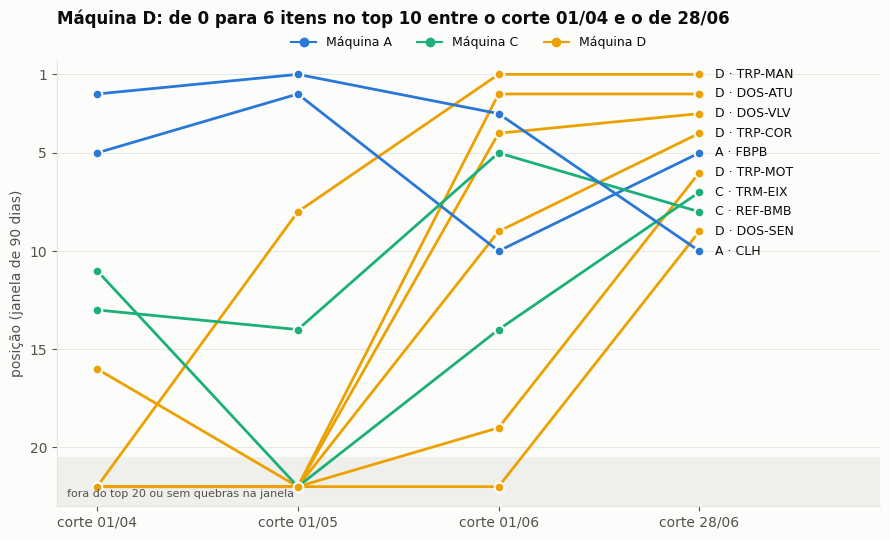

In [11]:
LIMITE = 20                                   # posições piores que isto vão para a faixa "fora do top 20"
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(posicoes.columns))
destaque = posicoes.loc[top_atual].sort_values(ultimo)
fora = LIMITE + 2
ax.axhspan(LIMITE + 0.5, fora + 1, color=GRADE, alpha=0.5, linewidth=0)
ax.text(-0.15, fora + 0.4, f"fora do top {LIMITE} ou sem quebras na janela", fontsize=8, color=TINTA_2, va="center")
maquinas_presentes = []
for item, linha in destaque.iterrows():
    maq = item.split(" · ")[0]
    maquinas_presentes.append(maq)
    cor = CAT["ABCD".index(maq)]
    v = linha.to_numpy(dtype=float)
    v = np.where(np.isnan(v) | (v > LIMITE), fora, v)
    ax.plot(x, v, "-o", color=cor, linewidth=2, markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.text(x[-1] + 0.08, v[-1], item, va="center", fontsize=9, color=TINTA)
ax.set_xticks(x, [f"corte {c}" for c in posicoes.columns])
ax.set_ylim(fora + 1, 0.3)
ax.set_xlim(-0.2, len(x) - 1 + 0.9)
ax.set_yticks([1, 5, 10, 15, 20])
ax.set_ylabel("posição (janela de 90 dias)")
ax.grid(axis="x", visible=False)
for maq, cor in zip("ABCD", CAT):
    if maq in maquinas_presentes:
        ax.plot([], [], "-o", color=cor, label=f"Máquina {maq}")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
primeiro = posicoes.columns[0]
conta = lambda col: posicoes[col].nsmallest(10).index.str[0].value_counts()
antes, depois = conta(primeiro), conta(ultimo)
maq_sobe = (depois.reindex(list("ABCD"), fill_value=0) - antes.reindex(list("ABCD"), fill_value=0)).idxmax()
ax.set_title(f"Máquina {maq_sobe}: de {antes.get(maq_sobe, 0)} para {depois.get(maq_sobe, 0)} itens no top 10 "
             f"entre o corte {primeiro} e o de {ultimo}", pad=26)
plt.tight_layout()

### 1.6 O mesmo método em outros níveis

Com o mesmo código, mudando só o agrupamento: por **equipamento** (o subsistema do MES) e por **máquina**. No nível de máquina, o resultado serve como **validação de bom senso**: a máquina A, que é o gargalo, deveria aparecer no topo, e de fato aparece entre as duas primeiras.

In [12]:
def ranking_nivel(nivel):
    c = pz.criterios(q, INICIO, FIM, IMPACTO, nivel=nivel)
    return pz.ranking(c, w)[["posicao", *nivel, "score", "quebras", "horas", "mttr_h", "reincidentes", "laplace_U"]]

display(ranking_nivel(("maquina",)))
ranking_nivel(("maquina", "equipamento")).head(10)

,posicao,maquina,score,quebras,horas,mttr_h,reincidentes,laplace_U
0,1,D,82.60,208,448.19,2.15,84,8.80
1,2,A,81.83,162,391.02,2.41,82,0.30
2,3,C,71.54,147,444.13,3.02,29,2.42
3,4,B,56.85,191,194.93,1.02,55,1.32


,posicao,maquina,equipamento,score,quebras,horas,mttr_h,reincidentes,laplace_U
0,1,A,AQUECIMENTO,91.13,68,197.30,2.90,37,0.94
1,2,D,TRANSPORTADOR,66.78,55,141.27,2.57,34,5.58
2,3,D,DOSADOR,63.09,53,126.04,2.38,31,5.31
3,4,A,ROLOS,55.17,58,100.55,1.73,34,-1.32
4,5,C,REFRIGERACAO,48.38,37,106.83,2.89,8,2.02
5,6,B,ALIMENTADOR,47.37,53,48.16,0.91,21,1.79
6,7,C,TRANSMISSAO,46.32,33,105.77,3.21,9,1.29
7,8,C,TRACIONADOR,38.99,31,86.21,2.78,8,0.45
8,9,B,PRENSA,38.61,47,51.25,1.09,14,0.17
9,10,B,HIDRAULICA,37.27,38,36.36,0.96,12,1.13


## 2. Sinais de deterioração

O case não pede prever a data da próxima quebra, e sim identificar comportamentos que justifiquem revisar o plano: **falhas mais frequentes, intervalos menores entre elas e reparos mais demorados**.

### Antes de tudo: o que é um "teste estatístico" e o tal "p"

Um teste estatístico responde: **"isso que eu estou vendo pode ter acontecido só por sorte?"**. Se você joga uma moeda 10 vezes e sai 6 caras, é sorte normal. Se sai 10 caras, é muito difícil ser sorte: a moeda provavelmente está viciada.

O **p-valor** é a chance de ver um resultado tão extremo **se nada estivesse mudando**. Quanto menor o p, menos provável que seja sorte. Os limites usuais são 0,05 ou 0,10 (5% ou 10% de chance de ser sorte).

### 2.1 Método

| Sinal | Ferramenta | Como ler |
|---|---|---|
| **Frequência crescente / intervalos menores** | **Teste de Laplace** sobre os instantes das quebras na janela (0, T]. Se a taxa de quebras fosse constante, U seguiria a curva do sino centrada em 0. | U > 0: as quebras se concentram no fim do período. É o teste clássico de tendência para equipamentos que são consertados e voltam a operar (MIL-HDBK-189; Ascher & Feingold, 1984). |
| **Quanto está piorando** | **Modelo de potência (Crow-AMSAA)**: taxa de falhas proporcional a $t^(β−1)$ | β > 1: piorando; β = 1: constante; β < 1: melhorando. β = 2 significa que a taxa dobrou entre o meio e o fim do período. |
| **Reparos mais longos** | **τ de Kendall** entre a ordem no tempo e a duração das quebras (teste de Mann-Kendall), com 6 ou mais quebras | τ > 0 com p ≤ 0,05: o tempo de reparo está crescendo. |
| **Muitos testes ao mesmo tempo** | **Benjamini-Hochberg** sobre os p-valores do Laplace | Com 70+ componentes testados, alguns dariam "significativo" por puro acaso. O ajuste limita a fração de alarmes falsos entre os alertas a 10%. |

**Teste de Laplace, com uma gangorra:** coloque o período numa régua e um pesinho em cada data de quebra. Se as quebras estão espalhadas por igual, a régua se equilibra **no meio**. Se elas se acumulam no fim, a régua pende para a direita. O U mede **o quanto o ponto de equilíbrio se afastou do meio**, descontando o que seria esperado por acaso.

**Crow-AMSAA, o "velocímetro" da piora:** o Laplace diz **se** está piorando; o Crow-AMSAA diz **quanto**. Ele ajusta uma curva às quebras acumuladas e resume o formato num número, o β. Pense num carro: β = 1 é velocidade constante; β > 1 é acelerando; β < 1 é freando. Foi criado para acompanhar a confiabilidade de sistemas em desenvolvimento (normas militares americanas) e é muito usado em manutenção.

**τ de Kendall (Mann-Kendall):** pega todos os pares de quebras e pergunta, para cada par, "a quebra mais recente demorou mais para consertar que a mais antiga?". Se a resposta for "sim" bem mais vezes do que "não", τ é positivo: os reparos estão ficando mais longos. Como só olha "maior ou menor", um reparo absurdamente longo não distorce o resultado.

**Benjamini-Hochberg, o problema das muitas moedas:** se você testar 74 moedas honestas, alguma vai dar "10 caras seguidas" só por azar. Do mesmo jeito, testando 74 componentes, alguns parecerão piorar por acaso. O método de Benjamini-Hochberg **ajusta os p-valores** levando em conta quantos testes foram feitos, para que, entre os componentes marcados como "alerta", no máximo cerca de 10% sejam alarmes falsos. Por que 10% e não 5%: um alarme falso aqui só custa uma inspeção; deixar passar uma piora real custa uma quebra.

**Classificação:**
- **Alerta:** tendência significativa **depois** do ajuste de Benjamini-Hochberg (p ajustado ≤ 0,10).
- **Atenção:** p ≤ 0,10 **sem** o ajuste, ou tempo de reparo crescendo.
- **Estável:** o resto.

**Índice de risco ("horas em risco"):** quebras projetadas para os próximos 30 dias pelo modelo de potência × MTTR do componente × criticidade da máquina. Não é previsão de data; é uma **ordem de grandeza** para comparar componentes: "se a tendência atual continuar, quantas horas de produção esse componente deve custar no próximo mês?".

In [13]:
det_maq = pz.deterioracao(q, INICIO, FIM, IMPACTO, nivel=("maquina",))
det_maq[["maquina", "quebras", "quebras_1a_metade", "quebras_2a_metade", "laplace_U", "p_tendencia", "beta",
         "tau_mttr", "p_mttr", "sinal"]]

,maquina,quebras,quebras_1a_metade,quebras_2a_metade,laplace_U,p_tendencia,beta,tau_mttr,p_mttr,sinal
0,D,208,48,160,8.80,0.00,1.92,0.27,0.00,alerta
1,C,147,62,85,2.42,0.01,1.18,-0.08,0.14,alerta
2,B,191,84,107,1.32,0.09,1.03,-0.03,0.56,atenção
3,A,162,89,73,0.30,0.38,0.93,-0.19,0.00,estável


**Como ler a tabela:** `quebras_1a_metade` e `quebras_2a_metade` dividem o período ao meio; `laplace_U` e `p_tendencia` vêm do teste da gangorra; `beta` é o "velocímetro" (Crow-AMSAA); `tau_mttr` e `p_mttr` dizem se os reparos estão ficando mais longos (τ > 0) ou mais curtos (τ < 0). A máquina D tem 48 quebras na primeira metade e 160 na segunda: um caso evidente de piora. A máquina A está estável, com reparos ficando **mais curtos** (τ negativo).

**O padrão da máquina A é crônico, não de piora.** No conjunto, as quebras da A não aumentaram ao longo do semestre. O que a diferencia é a **repetição**: a mesma falha volta no mesmo componente em poucos dias. É o "ciclo de reparo, retorno e nova falha do mesmo tipo" descrito no case.

**Analogia:** um paciente crônico não está necessariamente piorando; ele volta ao médico toda semana com o mesmo problema, porque o tratamento alivia o sintoma mas não cura. A tabela abaixo mostra isso em números: a porcentagem de quebras que se repetem no mesmo componente em até 7 dias, por máquina, e os componentes da A em que isso mais acontece (só os com 8 ou mais quebras, para a porcentagem não ser fruto de poucos casos).

In [14]:
reinc = q.assign(reincidente=pz.marcar_reincidencia(q))
por_maquina = reinc.groupby("maquina").agg(quebras=("id_parada", "size"), reincidentes=("reincidente", "sum"))
por_maquina["% reincidente (≤ 7 dias)"] = 100 * por_maquina["reincidentes"] / por_maquina["quebras"]
display(por_maquina)

cronicos = (reinc.query("maquina == 'A'").groupby("componente")
                 .agg(quebras=("id_parada", "size"), reincidentes=("reincidente", "sum"),
                      horas=("duracao_h", "sum"))
                 .query("quebras >= 8").sort_values("reincidentes", ascending=False).head(6))
cronicos["% reincidente"] = 100 * cronicos["reincidentes"] / cronicos["quebras"]
cronicos

,quebras,reincidentes,% reincidente (≤ 7 dias)
maquina,,,
A,162,82,50.62
B,191,55,28.80
C,147,29,19.73
D,208,84,40.38


,quebras,reincidentes,horas,% reincidente
componente,,,,
CLH,25,19,31.68,76.00
FD,22,15,17.60,68.18
RMPF,19,13,28.18,68.42
FBPB,15,9,48.55,60.00
RDFD,10,6,39.95,60.00
LMDTR,11,5,42.13,45.45


In [15]:
det = pz.deterioracao(q, INICIO, FIM, IMPACTO)
print(f"{len(det)} componentes com 4+ quebras testados:", det["sinal"].value_counts().to_dict())
det.query("sinal != 'estável'")[["maquina", "componente", "sinal", "quebras", "quebras_1a_metade",
                                 "quebras_2a_metade", "laplace_U", "p_ajustado", "beta", "tau_mttr",
                                 "mttr_h", "quebras_proj", "horas_em_risco"]]

74 componentes com 4+ quebras testados: {'estável': 45, 'atenção': 19, 'alerta': 10}


,maquina,componente,sinal,quebras,quebras_1a_metade,quebras_2a_metade,laplace_U,p_ajustado,beta,tau_mttr,mttr_h,quebras_proj,horas_em_risco
0,D,TRP-MAN,alerta,27,1,26,4.18,0.00,2.68,0.54,2.73,14.06,26.83
1,A,LOF,alerta,5,1,4,2.44,0.07,3.73,NaN,4.86,3.97,19.27
2,A,FBPB,alerta,15,4,11,2.53,0.06,2.06,-0.33,3.24,5.72,18.51
3,D,DOS-ATU,alerta,27,5,22,3.97,0.00,2.28,0.14,1.86,11.60,15.09
4,D,DOS-VLV,alerta,14,2,12,3.17,0.02,2.41,-0.12,3.07,6.41,13.78
5,D,DOS-SEN,alerta,8,0,8,2.57,0.06,3.42,0.36,3.41,5.67,13.53
6,D,TRP-COR,alerta,13,3,10,2.25,0.09,2.08,0.46,3.12,4.99,10.89
7,D,TRP-MOT,alerta,14,4,10,2.67,0.06,2.18,0.23,1.78,5.70,7.10
8,C,REF-TUB,alerta,7,1,6,2.26,0.09,2.45,0.24,2.91,3.27,6.65
9,A,GRAL,alerta,7,1,6,2.81,0.05,1.37,-0.29,0.35,1.67,0.59


**O que a saída mostra:** dos 74 componentes com 4 ou mais quebras, 10 estão em **alerta**, 19 em **atenção** e 45 **estáveis**. A tabela lista os que não estão estáveis, com as quebras projetadas para os próximos 30 dias (`quebras_proj`) e as horas em risco.

**Como ler o gráfico abaixo:** a "escada" é o número acumulado de quebras ao longo do tempo (sobe um degrau a cada quebra). A linha tracejada é o que se esperaria se as quebras viessem num **ritmo constante** (mesmo total, distribuído por igual). Uma escada que fica **abaixo** da linha e depois **acelera** é deterioração: as quebras vieram no fim. Mostramos os dois componentes em alerta com mais quebras da máquina A e os dois das outras máquinas.

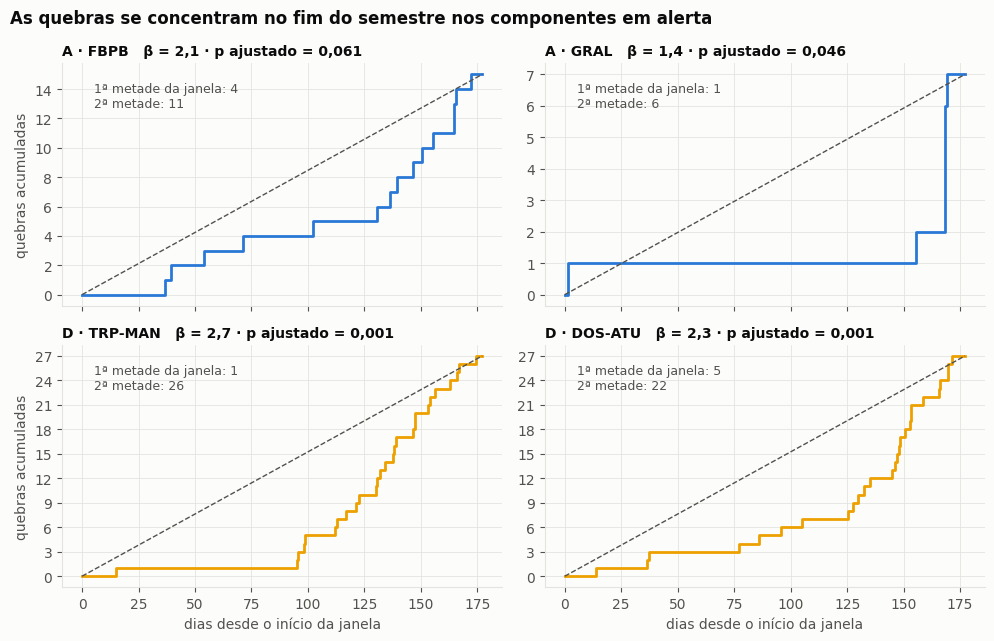

In [16]:
alertas = det.query("sinal == 'alerta'")
escolhidos = pd.concat([alertas.query("maquina == 'A'").nlargest(2, "quebras"),
                        alertas.query("maquina != 'A'").nlargest(2, "quebras")])

fig, eixos = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
T_dias = (FIM - INICIO) / pd.Timedelta(days=1)
for ax, (_, d) in zip(eixos.flat, escolhidos.iterrows()):
    t = q.query("maquina == @d.maquina and componente == @d.componente")["inicio"].sort_values()
    dias = ((t - INICIO) / pd.Timedelta(days=1)).to_numpy()
    n = len(dias)
    cor = CAT["ABCD".index(d.maquina)]
    ax.step(np.r_[0, dias, T_dias], np.r_[0, np.arange(1, n + 1), n], where="post", color=cor, linewidth=2)
    ax.plot([0, T_dias], [0, n], "--", color=TINTA_2, linewidth=1)
    ax.set_title(f"{d.maquina} · {d.componente}   β = {d.beta:.1f} · p ajustado = {d.p_ajustado:.3f}".replace(".", ","),
                 fontsize=10)
    ax.text(T_dias * 0.03, n * 0.85, f"1ª metade da janela: {d.quebras_1a_metade}\n"
            f"2ª metade: {d.quebras_2a_metade}", fontsize=9, color=TINTA_2)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
for ax in eixos[-1]:
    ax.set_xlabel("dias desde o início da janela")
for ax in eixos[:, 0]:
    ax.set_ylabel("quebras acumuladas")
fig.suptitle("As quebras se concentram no fim do semestre nos componentes em alerta",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()

**Como ler o gráfico abaixo:** os 12 componentes em alerta ou atenção com mais **horas em risco** (horas paradas esperadas no próximo mês se a tendência continuar, já multiplicadas pela criticidade da máquina). Vermelho = alerta; amarelo = atenção.

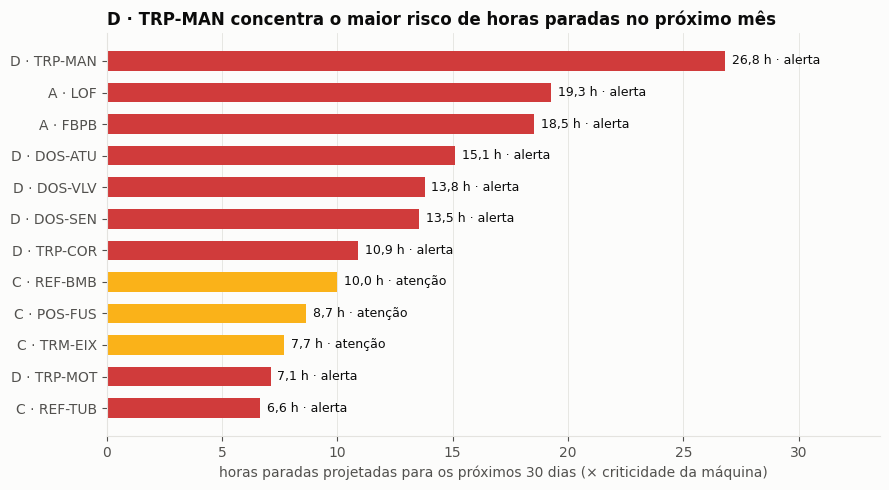

In [17]:
risco = det.query("sinal != 'estável'").nlargest(12, "horas_em_risco").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
cores = risco["sinal"].map(STATUS)
ax.barh(risco["maquina"] + " · " + risco["componente"], risco["horas_em_risco"], color=cores, height=0.62)
for y, (h, s) in enumerate(zip(risco["horas_em_risco"], risco["sinal"])):
    ax.text(h + 0.3, y, f"{h:.1f} h · {s}".replace(".", ","), va="center", fontsize=9, color=TINTA)
ax.set_xlabel("horas paradas projetadas para os próximos 30 dias (× criticidade da máquina)")
ax.set_xlim(0, risco["horas_em_risco"].max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title(f"{risco.iloc[-1].maquina} · {risco.iloc[-1].componente} concentra o maior risco "
             f"de horas paradas no próximo mês")
plt.tight_layout()

### 2.2 Validação: quantos alertas o método daria se nada estivesse piorando?

Um detector de fumaça que apita toda hora é inútil, mesmo que nunca deixe passar um incêndio. Precisamos saber **com que frequência o método dá alarme falso**.

**O teste (simulação):** criamos no computador **500 semestres falsos** em que nada está piorando: cada componente mantém o mesmo número de quebras que teve na realidade, mas as datas são **sorteadas por igual** ao longo do período (ritmo constante, sem tendência). Em cada semestre falso, passamos o procedimento inteiro (teste de Laplace + ajuste de Benjamini-Hochberg) e contamos quantos alertas aparecem. Como sabemos que não há piora nenhuma, **todo alerta ali é falso**.

É como testar um detector de fumaça numa sala sem fogo, 500 vezes. Se ele quase nunca apitar, os apitos na sala de verdade merecem atenção. Se a média de alarmes falsos ficar perto de zero, o método está "calibrado".

In [18]:
rng = np.random.default_rng(1)
T_h = (FIM - INICIO) / pz.H
ns = det["quebras"].to_numpy()
falsos = []
for _ in range(500):
    pv = pd.Series([pz.teste_laplace(rng.uniform(0, T_h, n), T_h)[1] for n in ns])
    falsos.append((pz.benjamini_hochberg(pv) <= pz.PARAM["ALFA_FDR"]).sum())
falsos = np.array(falsos)
print(f"Alertas em dados sem tendência: média {falsos.mean():.2f} por semestre; "
      f"em {np.mean(falsos == 0):.0%} das simulações, nenhum.")
print(f"Nos dados reais: {(det['sinal'] == 'alerta').sum()} alertas.")

Alertas em dados sem tendência: média 0.07 por semestre; em 94% das simulações, nenhum.
Nos dados reais: 10 alertas.


**O que a saída mostra:** em dados sem nenhuma tendência, o método dá em média só **0,07 alarme falso por semestre**, e em 94% das simulações não dá nenhum. Nos dados reais, deu 10 alertas. A diferença é grande demais para ser acaso: os alertas reais são sinais de verdade.

## 3. Efetividade das preventivas

### 3.1 O que os dados permitem

A primeira coisa a verificar é se a base tem ordens preventivas para analisar. A tabela abaixo cruza os tipos de ordem do SAP com os tipos de atividade.

In [19]:
display(pd.crosstab(sap["tipo"], sap["tipo_atividade"], margins=True, margins_name="total"))
print("Ordens do tipo preventiva na base:", sap["tipo"].str.contains("PREVENT", na=False).sum())

tipo_atividade,AJ,CO,CP,SD,total
tipo,,,,,
CORRETIVA,59,364,0,29,452
CORRETIVA PLANEJADA,131,0,810,159,1100
total,190,364,810,188,1552


Ordens do tipo preventiva na base: 0


**A base do SAP não tem nenhuma ordem preventiva.** Os únicos tipos são CORRETIVA e CORRETIVA PLANEJADA. Esse é um achado em si: ou as preventivas não são registradas como ordem no SAP, ou foram filtradas na extração. De qualquer forma, **com estes dados não é possível medir diretamente a efetividade do plano preventivo**.

O que dá para responder é uma pergunta parecida, que serve de **proxy** (uma medida "substituta"): *depois de uma intervenção planejada num componente, a próxima quebra dele demora mais do que depois de um reparo emergencial?* Se a intervenção planejada não aumenta o tempo até a próxima falha, há indício de que o reparo ataca o sintoma e não a causa, exatamente o ciclo descrito no case.

### 3.2 Método: curvas de sobrevivência

- **Unidade:** cada intervenção num evento MES + SAP com ligação de confiança alta ou média, não ambígua e com componente conhecido. Ligações duvidosas ficam de fora para não misturar eventos errados.
- **O que medimos:** quantos dias se passaram do fim daquela parada até o início da próxima quebra do **mesmo componente**.
- **O problema das histórias "sem final" (censura):** se o componente não quebrou de novo até o fim dos dados, não sabemos quanto tempo ele vai durar; sabemos só que durou **pelo menos** até ali. Essa observação é chamada de **censurada**. É como medir quanto tempo as pessoas ficam num emprego olhando só os últimos 6 meses: quem ainda está empregado não "saiu", mas também não dá para dizer que fica para sempre. Jogar essas pessoas fora faria parecer que todo mundo sai rápido.
- **Kaplan-Meier:** calcula, dia a dia, a **porcentagem de componentes que ainda não quebraram de novo**, aproveitando corretamente as observações censuradas (elas contam como "ainda funcionando" enquanto foram observadas e depois simplesmente saem da conta). O resultado é uma "escada" que começa em 100% e vai descendo: a **curva de sobrevivência**.
- **Log-rank estratificado por máquina:** o teste log-rank compara duas curvas de sobrevivência e diz se a diferença é maior do que o acaso explicaria. "Estratificado por máquina" quer dizer que a comparação é feita **dentro de cada máquina** e depois combinada. 🔧 Sem isso, o resultado seria distorcido: as máquinas quebram em ritmos muito diferentes e têm proporções diferentes de cada tipo de ordem. É como comparar dois remédios separando por faixa de idade: se um foi dado mais a idosos, misturar todo mundo faria esse remédio parecer pior só por causa da idade dos pacientes.
- **RMST de 30 dias** (*restricted mean survival time*, tempo médio sem quebra limitado a 30 dias): é a **área debaixo da curva** de sobrevivência nos primeiros 30 dias, ou seja, quantos dias sem quebra, em média, um componente "ganha" no primeiro mês após a intervenção. É um resumo mais estável do que a mediana, que às vezes nem existe (quando mais da metade dos componentes não quebrou de novo).

Quando a base tiver ordens preventivas, a mesma função (`pz.tempo_ate_proxima_quebra`, parâmetro `tipos`) compara preventiva × corretiva sem mudar nada.

In [20]:
sobrev = pz.tempo_ate_proxima_quebra(eventos, q, FIM, tipos=("CORRETIVA PLANEJADA", "CORRETIVA"))
sobrev["grupo_maquina"] = np.where(sobrev["maquina"] == "A", "Máquina A", "Máquinas B–D")
print(f"{len(sobrev)} intervenções; {sobrev['quebrou'].mean():.0%} tiveram nova quebra no mesmo componente.")

tabelas = []
for g, d in sobrev.groupby("grupo_maquina"):
    t, (_, lr) = pz.comparar_grupos(d, "tipo", horizonte_d=30)
    tabelas.append(t.assign(grupo_maquina=g))
resumo_sobrev = pd.concat(tabelas)[["grupo_maquina", "grupo", "n", "quebraram", "sem_quebra_em_30d",
                                    "mediana_dias", "rmst_dias"]]
chi2, p_lr, ref = pz.logrank_estratificado(sobrev, "tipo", "maquina")
print(f"Log-rank estratificado por máquina: qui² = {chi2:.2f}, p = {p_lr:.3f}")
resumo_sobrev

1036 intervenções; 80% tiveram nova quebra no mesmo componente.


c:\Users\girle\Desktop\Yan\1. UFPE\2026.2\COMPET - - MOURA\moura_manutencao\src\scripts\priorizacao.py:273: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~eventos["ambiguo"].fillna(False).astype(bool)


Log-rank estratificado por máquina: qui² = 1.83, p = 0.176


,grupo_maquina,grupo,n,quebraram,sem_quebra_em_30d,mediana_dias,rmst_dias
0,Máquina A,CORRETIVA,21,11,0.60,90.91,21.13
1,Máquina A,CORRETIVA PLANEJADA,86,42,0.60,80.57,21.88
0,Máquinas B–D,CORRETIVA,308,256,0.28,14.01,15.45
1,Máquinas B–D,CORRETIVA PLANEJADA,621,522,0.32,15.66,16.75


**O que a saída mostra:** foram 1.036 intervenções, e 80% delas tiveram nova quebra no mesmo componente dentro do período. O log-rank estratificado dá p = 0,176: a diferença entre planejada e emergencial **não é significativa** (há cerca de 18% de chance de uma diferença desse tamanho aparecer só por acaso). Na tabela, `sem_quebra_em_30d` é a fração de componentes ainda sem quebra 30 dias depois, e `rmst_dias` é o tempo médio sem quebra no primeiro mês: os valores dos dois tipos de intervenção ficam muito próximos.

**Como ler o gráfico abaixo:** cada curva começa em 100% (logo após a intervenção, nenhum componente quebrou ainda) e desce a cada nova quebra. Curva mais alta = componentes que aguentam mais tempo sem quebrar. Se a intervenção planejada fosse mais efetiva, a curva azul ficaria claramente acima da laranja.

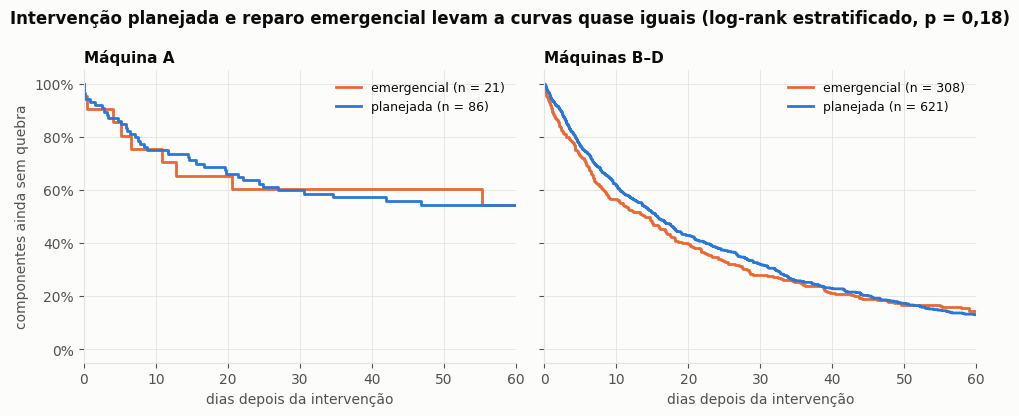

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
cor_tipo = {"CORRETIVA PLANEJADA": CAT[0], "CORRETIVA": CAT[1]}
nome_tipo = {"CORRETIVA PLANEJADA": "planejada", "CORRETIVA": "emergencial"}
for ax, (g, d) in zip(eixos, sobrev.groupby("grupo_maquina")):
    for tipo, dt in d.groupby("tipo"):
        sf = pz.kaplan_meier(dt["dias"].to_numpy(), dt["quebrou"].to_numpy())
        x = np.r_[0, sf.quantiles]
        y = np.r_[1, sf.probabilities]
        ax.step(x, y, where="post", color=cor_tipo[tipo], linewidth=2, label=f"{nome_tipo[tipo]} (n = {len(dt)})")
    ax.set_xlim(0, 60)
    ax.set_title(g, fontsize=11)
    ax.set_xlabel("dias depois da intervenção")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
    ax.legend(fontsize=9, loc="upper right")
eixos[0].set_ylabel("componentes ainda sem quebra")
fig.suptitle(f"Intervenção planejada e reparo emergencial levam a curvas quase iguais "
             f"(log-rank estratificado, p = {p_lr:.2f})".replace(".", ","), x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()

### 3.3 O que seria preciso para revisar periodicidades e planos com segurança

1. **Ordens preventivas registradas no SAP**, com o tipo, o plano de manutenção de origem e o item da lista de tarefas executado. É o dado que falta para a comparação direta.
2. **Componente e ação em campos próprios na ordem**, e não só no texto livre. Os campos de fechamento do chamado (componente, modo de falha, ação, peças) já resolvem isso daqui em diante; para o histórico, a classificação do Subproduto 3.
3. **Data da última preventiva por componente**, para medir quanto tempo havia passado desde a última intervenção no momento de cada quebra. 💡 Isso permite desenhar a "curva da banheira" de cada componente: muitas falhas no começo (defeitos de montagem), poucas no meio (vida útil) e muitas no fim (desgaste), como o formato de uma banheira vista de lado.
4. **Inspeções com resultado**: "inspecionado, ok" também é informação. Sem isso, o efeito da inspeção é invisível.
5. **Peças trocadas, com código do material**, para separar troca de ajuste e estimar a vida útil de cada peça (pela distribuição de Weibull, o modelo padrão de "tempo até falhar" em engenharia de confiabilidade).
6. **Período maior.** Seis meses mostram tendência, mas não bastam para estimar a vida de componentes que quebram poucas vezes por ano.

## 4. Saídas

As tabelas ficam em `data/processed/` para carregar no Supabase (o banco de dados do app), como a conciliação. A aba de indicadores pode então mostrar o ranking e os alertas, com o mesmo clique até os eventos de origem. Os itens têm `maquina` e `componente`, que são as chaves do evento conciliado.

Cada tabela é salva em dois formatos: `.pkl` (formato do Python, que preserva os tipos de cada coluna, para os próximos scripts) e `.csv` com ponto e vírgula e vírgula decimal (abre direto no Excel em português).

In [23]:
OUT_DIR = Path("./data/processed/priorizacao"); OUT_DIR.mkdir(exist_ok=True, parents=True)
saidas = {
    "ranking_semestre": r_semestre,
    "ranking_movel": movel,
    "sensibilidade": sens,
    "deterioracao": det,
    "sobrevivencia": sobrev,
}
for nome, df in saidas.items():
    df.to_parquet(OUT_DIR / f"{nome}.parquet", index=False)
    df.to_csv(OUT_DIR / f"{nome}.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
    print(f"{nome:24s} {len(df):>5} linhas")

ranking_semestre           112 linhas
ranking_movel              386 linhas
sensibilidade              112 linhas
deterioracao                74 linhas
sobrevivencia             1036 linhas


## 5. Limitações

- **Máquinas B, C e D são fictícias.** Os sinais fortes de piora nelas (por exemplo, quase todas as quebras no segundo trimestre) parecem padrões inseridos para testar o método. A detecção mostra que o método funciona, mas as conclusões de engenharia valem para a máquina A.
- **O componente é o do MES**, anotado pela Produção (o principal da parada). Erros de anotação ali entram direto no ranking.
- **Seis meses de dados.** O teste de Laplace detecta tendências fortes; tendências suaves e variações sazonais (de estação do ano) ficam fora do alcance.
- **O modelo de potência projeta a tendência atual para frente.** Se uma ação corretiva já foi tomada, a projeção exagera o risco. Por isso o índice serve para comparar componentes, não para prever datas.
- **A análise de intervenções é observacional** (só observamos o que aconteceu, sem poder sortear quem recebe cada tipo de intervenção). A escolha entre intervenção planejada e emergencial não é aleatória: a planejada costuma ser feita quando o problema é menos urgente. A estratificação por máquina reduz esse viés, mas não o elimina.
- **Sem custo.** O impacto é medido em horas ponderadas pela criticidade da máquina.

## Referências

- Ascher, H.; Feingold, H. *Repairable Systems Reliability: Modeling, Inference, Misconceptions and Their Causes*. Marcel Dekker, 1984. *(Referência clássica sobre análise de falhas de equipamentos que são consertados e voltam a operar; base do teste de Laplace neste contexto.)*
- Benjamini, Y.; Hochberg, Y. "Controlling the false discovery rate: a practical and powerful approach to multiple testing". *Journal of the Royal Statistical Society B*, v. 57, n. 1, p. 289–300, 1995. *(Método de ajuste para muitos testes ao mesmo tempo.)*
- Crow, L. H. "Reliability analysis for complex, repairable systems". In: Proschan, F.; Serfling, R. J. (eds.). *Reliability and Biometry*. SIAM, 1974, p. 379–410. *(Origem do modelo de potência Crow-AMSAA.)*
- Kaplan, E. L.; Meier, P. "Nonparametric estimation from incomplete observations". *Journal of the American Statistical Association*, v. 53, n. 282, p. 457–481, 1958. *(Curva de sobrevivência com observações censuradas.)*
- Saaty, T. L. *The Analytic Hierarchy Process*. McGraw-Hill, 1980. *(Método AHP de comparação par a par para definir pesos.)*
- U.S. Department of Defense. *MIL-HDBK-189C: Reliability Growth Management*, 2011. *(Manual que padroniza o acompanhamento de tendência de falhas.)*